<a href="https://colab.research.google.com/github/Areeha548/CNN_Assignment_Traffic_Signs/blob/main/CNN_Assignment_Traffic_Signs_Solved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN Assignment — Reading the Road: Traffic Sign Recognition

**Level:** Intermediate · **Suggested time:** 1–2 weeks · **Frameworks:** TensorFlow/Keras *or* PyTorch

## The scenario
You have joined the perception team at a self-driving car startup. The car's camera captures the road, and your job is to build a CNN that reads a cropped photo of a single traffic sign and says *which of 43 signs it is*. The data (GTSRB) is genuinely messy — variable size, lighting, blur, and class imbalance — and that is exactly where the interesting decisions live.

> **How this notebook works:** each step gives you a little starter code, a set of **Hints**, and a **TODO** checklist. You write the rest. Pick one framework and stick with it. Set a seed, use a GPU (Colab: *Runtime → Change runtime type → GPU*).


### Setup
**Hints**
- Import only what your chosen framework needs; delete the other block.
- Fix every random seed you can (`numpy`, and your framework's) so results are reproducible.

**TODO**
- [ ] Import your libraries
- [ ] Set a global `SEED`
- [ ] Detect and print whether a GPU is available


In [1]:
# 1. Import libraries and prepare the computer
import os
import random
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cu130
Device: cuda
GPU available: True


---
## Part A — Explore the data  *(10%)*

**Hints**
- Load with `torchvision.datasets.GTSRB(root, split='train', download=True)` **or** `tensorflow_datasets.load('gtsrb')`, or a Kaggle folder/CSV.
- To build a label list fast in torchvision, the `(path, label)` pairs live in `dataset._samples`.
- Imbalance matters later (Part D): note which classes are rare *now*.
- Don't load every image just to measure sizes — sample a few hundred.

**TODO**
- [ ] A1: load train + test, print how many images in each and how many classes
- [ ] A2: show a 5×5 grid of random training images **with their labels**
- [ ] A3: plot a histogram of class frequencies; name the 3 rarest classes
- [ ] A4: report min / median / max image width and height


In [2]:
# A1. Download the GTSRB traffic-sign dataset
# The first run downloads the data. Internet access is required only for this step.
DATA_DIR = "./data"

train_raw = datasets.GTSRB(root=DATA_DIR, split="train", download=True)
test_raw = datasets.GTSRB(root=DATA_DIR, split="test", download=True)

NUM_CLASSES = 43
train_labels = [label for _, label in train_raw._samples]
test_labels = [label for _, label in test_raw._samples]

print("Training images:", len(train_raw))
print("Testing images :", len(test_raw))
print("Number of classes:", NUM_CLASSES)
print("Unique training classes:", len(set(train_labels)))

100%|██████████| 187M/187M [00:18<00:00, 10.0MB/s]
100%|██████████| 89.0M/89.0M [00:09<00:00, 8.97MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 183kB/s]


Training images: 26640
Testing images : 12630
Number of classes: 43
Unique training classes: 43


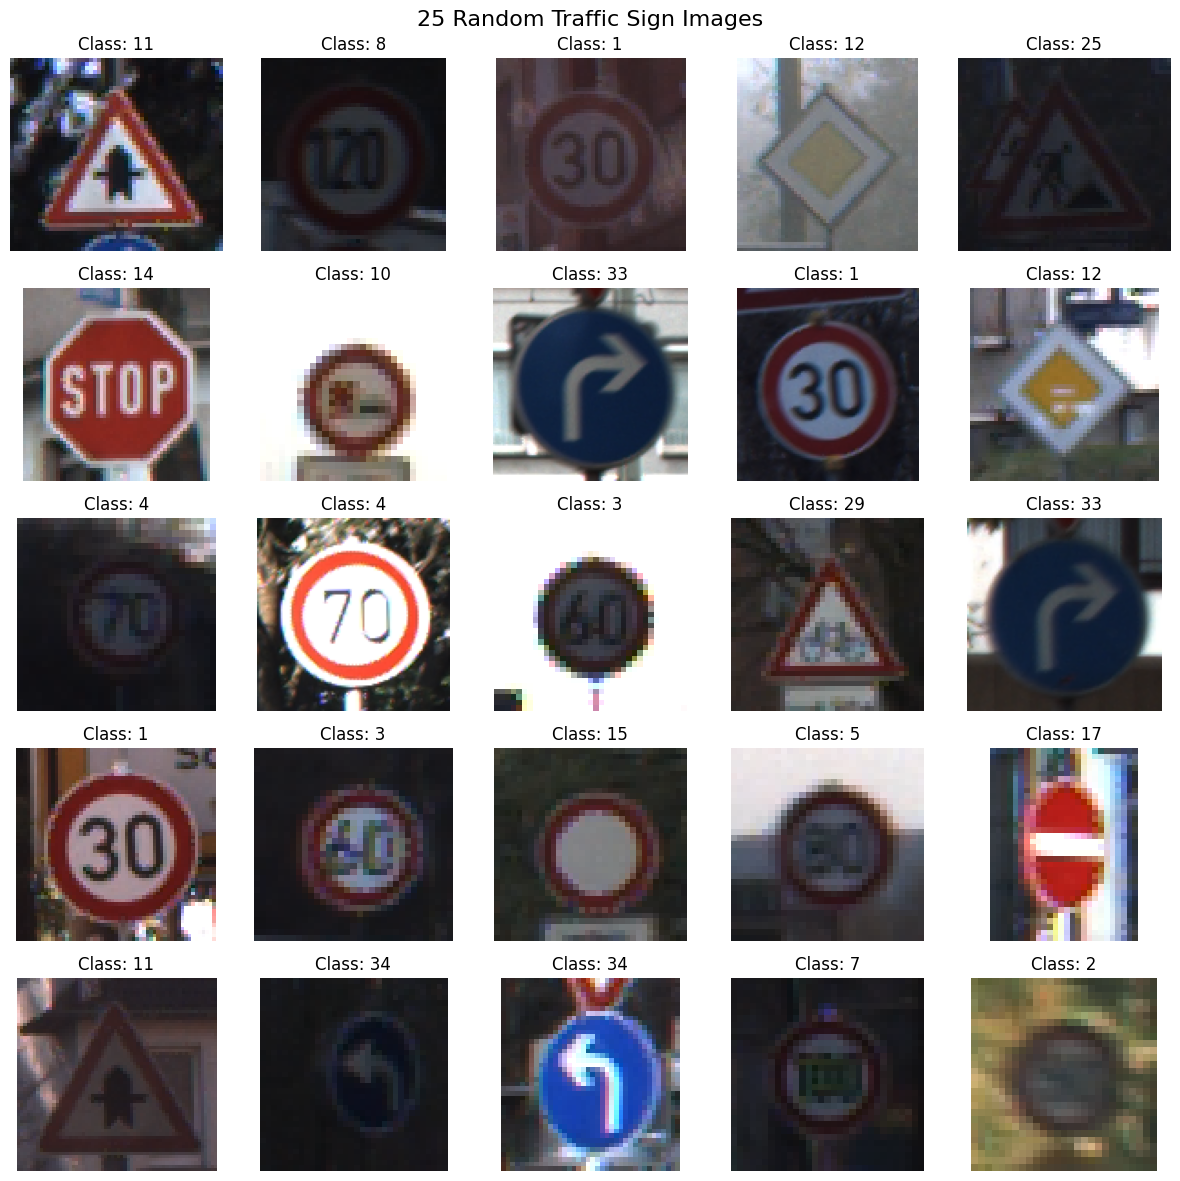

In [3]:
# A2. Display 25 random training images and their class labels
fig, axes = plt.subplots(5, 5, figsize=(12, 12))
random_indices = np.random.choice(len(train_raw), 25, replace=False)

for ax, idx in zip(axes.flat, random_indices):
    image, label = train_raw[idx]
    ax.imshow(image)
    ax.set_title(f"Class: {label}")
    ax.axis("off")

plt.suptitle("25 Random Traffic Sign Images", fontsize=16)
plt.tight_layout()
plt.show()

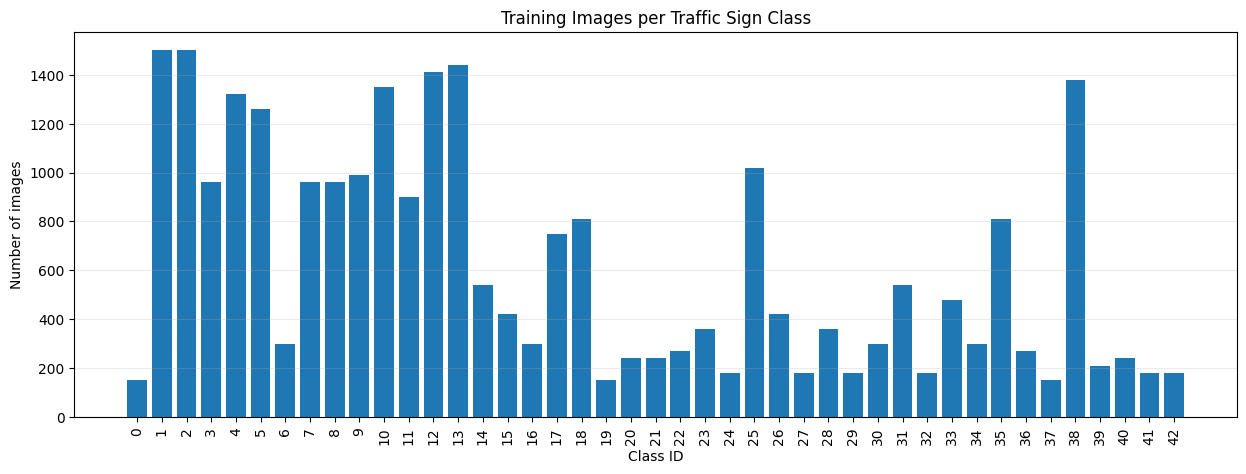

Three rarest classes (class ID, image count): [(0, 150), (19, 150), (37, 150)]


In [4]:
# A3. Count images in every class and find the 3 rarest classes
class_counts = Counter(train_labels)
class_ids = list(range(NUM_CLASSES))
counts = [class_counts[class_id] for class_id in class_ids]

plt.figure(figsize=(15, 5))
plt.bar(class_ids, counts)
plt.xlabel("Class ID")
plt.ylabel("Number of images")
plt.title("Training Images per Traffic Sign Class")
plt.xticks(class_ids, rotation=90)
plt.grid(axis="y", alpha=0.25)
plt.show()

rarest_classes = sorted(class_counts.items(), key=lambda item: item[1])[:3]
print("Three rarest classes (class ID, image count):", rarest_classes)

In [5]:
# A4. Check original image width and height using a random sample
sample_size = min(500, len(train_raw))
sample_indices = np.random.choice(len(train_raw), sample_size, replace=False)

widths, heights = [], []
for idx in sample_indices:
    image, _ = train_raw[idx]
    width, height = image.size
    widths.append(width)
    heights.append(height)

print("Image width  - min / median / max:",
      min(widths), int(np.median(widths)), max(widths))
print("Image height - min / median / max:",
      min(heights), int(np.median(heights)), max(heights))

Image width  - min / median / max: 26 43 221
Image height - min / median / max: 25 43 192


---
## Part B — Preprocess  *(10%)*

**Hints**
- Resize everything to one square size (32×32 or 48×48 are sensible). **Justify your choice in the report.**
- Scale pixels into [0,1] (torchvision `ToTensor()` already does this) or standardize per channel.
- Make the val split **stratified by class** so rare signs don't vanish from validation. A plain random split can drop a rare class entirely.
- Shuffle the *training* loader only; keep val/test in fixed order.

**TODO**
- [ ] B1/B2: define a resize+normalize transform (and a separate augmenting one later, in Part D)
- [ ] B3: build a stratified 80/20 train/val split
- [ ] B4: create train / val / test loaders (or `tf.data` pipelines) with batching


In [6]:
# B1 + B2. Resize images and convert pixel values to tensors
# 32x32 is small and fast, which makes CNN training easier on limited hardware.
# ToTensor converts pixel values from 0..255 into 0..1.
IMG_SIZE = 32
BATCH_SIZE = 64

basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

train_dataset = datasets.GTSRB(
    root=DATA_DIR, split="train", download=False, transform=basic_transform
)
test_dataset = datasets.GTSRB(
    root=DATA_DIR, split="test", download=False, transform=basic_transform
)

print("Preprocessing is ready.")
print("One image tensor shape:", train_dataset[0][0].shape)
print("Pixel range:", train_dataset[0][0].min().item(),
      "to", train_dataset[0][0].max().item())

Preprocessing is ready.
One image tensor shape: torch.Size([3, 32, 32])
Pixel range: 0.21176470816135406 to 1.0


In [7]:
# B3. Make a stratified 80% training / 20% validation split.
# Stratified means every class contributes approximately 80/20 to both sets.
labels_array = np.array(train_labels)
rng = np.random.default_rng(SEED)
train_indices, val_indices = [], []

for class_id in range(NUM_CLASSES):
    class_indices = np.where(labels_array == class_id)[0]
    rng.shuffle(class_indices)
    split_point = int(0.8 * len(class_indices))
    train_indices.extend(class_indices[:split_point].tolist())
    val_indices.extend(class_indices[split_point:].tolist())

rng.shuffle(train_indices)
rng.shuffle(val_indices)

train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(train_dataset, val_indices)

print("Training subset:", len(train_subset))
print("Validation subset:", len(val_subset))
print("Training percentage:", round(100 * len(train_subset) / len(train_dataset), 2))
print("Validation percentage:", round(100 * len(val_subset) / len(train_dataset), 2))

Training subset: 21312
Validation subset: 5328
Training percentage: 80.0
Validation percentage: 20.0


In [8]:
# B4. Create data loaders
# Only the training loader is shuffled.
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=0, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=0, pin_memory=torch.cuda.is_available())

images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Batch image shape: torch.Size([64, 3, 32, 32])
Batch label shape: torch.Size([64])


---
## Part C — Baseline CNN  *(25%)*

**Hints**
- Keep the baseline small: 2 blocks of Conv→ReLU→MaxPool, then Flatten→Dense→output.
- Output layer has **43 units**. In PyTorch leave them as raw logits (`CrossEntropyLoss` applies softmax internally); in Keras use `softmax` + `sparse_categorical_crossentropy`.
- Work out the flattened size: with IMG_SIZE=32 and two 2×2 pools you get 8×8 feature maps.
- Record **both** train and val metrics every epoch — you need them for the curves.

**TODO**
- [ ] C1: define the baseline CNN from scratch (no pretrained weights)
- [ ] C2: write/compile a training loop that logs train + val loss & accuracy per epoch
- [ ] C3: plot the learning curves
- [ ] C4: report **test accuracy** and interpret the curves (2–3 sentences)


In [9]:
# C1. Build a simple CNN from scratch.
# Input: 3 x 32 x 32 image. Output: 43 raw scores (logits), one per class.
class TrafficSignCNN(nn.Module):
    def __init__(self, dropout=0.0, use_batchnorm=False):
        super().__init__()

        layers = [
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
        ]
        if use_batchnorm:
            layers.append(nn.BatchNorm2d(32))
        layers += [nn.ReLU(), nn.MaxPool2d(2),
                   nn.Conv2d(32, 64, kernel_size=3, padding=1)]
        if use_batchnorm:
            layers.append(nn.BatchNorm2d(64))
        layers += [nn.ReLU(), nn.MaxPool2d(2)]

        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, NUM_CLASSES)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

baseline_model = TrafficSignCNN().to(DEVICE)
print(baseline_model)

TrafficSignCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=128, out_features=43, bias=True)
  )
)


In [10]:
# C2. Training and evaluation functions
# CrossEntropyLoss expects raw logits, so we do NOT apply softmax inside the model.
def run_epoch(model, loader, loss_function, optimizer=None):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.set_grad_enabled(is_training):
        for batch_images, batch_labels in loader:
            batch_images = batch_images.to(DEVICE)
            batch_labels = batch_labels.to(DEVICE)

            if is_training:
                optimizer.zero_grad()

            outputs = model(batch_images)
            loss = loss_function(outputs, batch_labels)

            if is_training:
                loss.backward()
                optimizer.step()

            batch_size = batch_labels.size(0)
            total_loss += loss.item() * batch_size
            predictions = outputs.argmax(dim=1)
            correct += (predictions == batch_labels).sum().item()
            total += batch_size

    return total_loss / total, correct / total


def train_model(model, train_dl, val_dl, epochs=10, learning_rate=0.001,
                class_weights=None):
    weights = class_weights.to(DEVICE) if class_weights is not None else None
    loss_function = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    history = {"train_loss": [], "val_loss": [],
               "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(model, train_dl, loss_function, optimizer)
        val_loss, val_acc = run_epoch(model, val_dl, loss_function)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch + 1:02d}/{epochs} | "
              f"Train loss: {train_loss:.4f}, acc: {train_acc:.4f} | "
              f"Val loss: {val_loss:.4f}, acc: {val_acc:.4f}")

    return history


EPOCHS = 10  # Increase to 15 or more if you have enough time/GPU.
baseline_history = train_model(
    baseline_model, train_loader, val_loader, epochs=EPOCHS
)

Epoch 01/10 | Train loss: 1.9084, acc: 0.4591 | Val loss: 0.7233, acc: 0.7860
Epoch 02/10 | Train loss: 0.4274, acc: 0.8763 | Val loss: 0.2614, acc: 0.9277
Epoch 03/10 | Train loss: 0.1887, acc: 0.9482 | Val loss: 0.1881, acc: 0.9473
Epoch 04/10 | Train loss: 0.1071, acc: 0.9695 | Val loss: 0.2094, acc: 0.9491
Epoch 05/10 | Train loss: 0.0817, acc: 0.9782 | Val loss: 0.0947, acc: 0.9784
Epoch 06/10 | Train loss: 0.0518, acc: 0.9869 | Val loss: 0.0839, acc: 0.9788
Epoch 07/10 | Train loss: 0.0368, acc: 0.9899 | Val loss: 0.0772, acc: 0.9825
Epoch 08/10 | Train loss: 0.0361, acc: 0.9902 | Val loss: 0.0742, acc: 0.9840
Epoch 09/10 | Train loss: 0.0295, acc: 0.9927 | Val loss: 0.1067, acc: 0.9762
Epoch 10/10 | Train loss: 0.0311, acc: 0.9916 | Val loss: 0.0766, acc: 0.9840


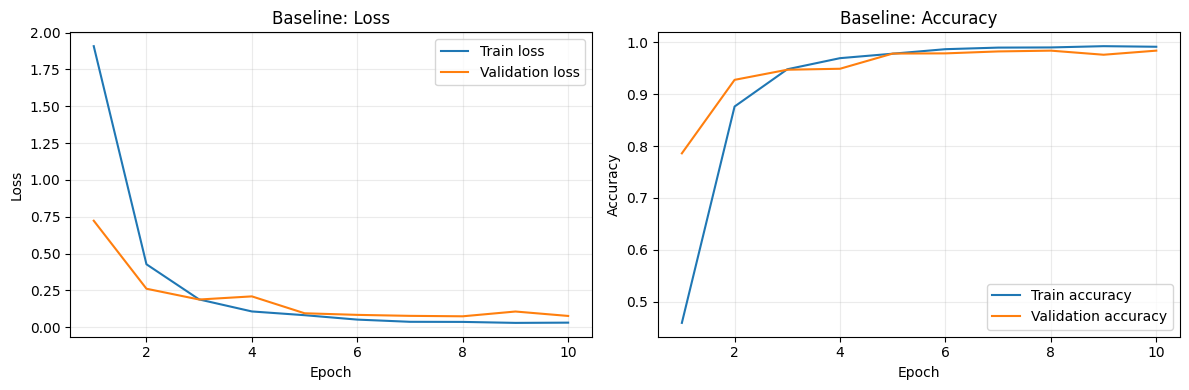

In [11]:
# C3. Plot training and validation loss/accuracy
epochs_range = range(1, len(baseline_history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, baseline_history["train_loss"], label="Train loss")
plt.plot(epochs_range, baseline_history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline: Loss")
plt.legend()
plt.grid(alpha=0.25)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, baseline_history["train_acc"], label="Train accuracy")
plt.plot(epochs_range, baseline_history["val_acc"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline: Accuracy")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [12]:
# C4. Evaluate the baseline on the separate test set
baseline_test_loss, baseline_test_acc = run_epoch(
    baseline_model, test_loader, nn.CrossEntropyLoss()
)
baseline_val_acc = max(baseline_history["val_acc"])

print(f"Baseline best validation accuracy: {baseline_val_acc * 100:.2f}%")
print(f"Baseline test accuracy: {baseline_test_acc * 100:.2f}%")

Baseline best validation accuracy: 98.40%
Baseline test accuracy: 86.53%


**C4 interpretation (write here):**

Compare the two accuracy curves and the two loss curves after running the notebook. If training accuracy keeps increasing but validation accuracy stops improving or decreases, and validation loss starts increasing, the model is overfitting. If both training and validation accuracy are low, the model is underfitting. If both accuracies improve and remain close, the model is learning reasonably well. Use the actual curves above to decide which case applies.

---
## Part D — Make it better  *(30%)*

Apply **at least three** techniques and measure **each** against the baseline.

**Hints**
- Change **one thing at a time** or you won't know what helped.
- Augmentation ideas: rotation, small shifts, zoom, brightness. **Do NOT flip horizontally** — it can turn a left-turn sign into a right-turn sign.
- Overfitting (val ≪ train)? → augmentation, dropout, batchnorm. Underfitting? → bigger/deeper net, train longer.
- Imbalance: pass class weights to the loss, or oversample rare classes.
- Transfer learning (MobileNetV2 / ResNet) is a strong comparison point.

**TODO**
- [ ] Pick ≥3 techniques and run them, logging val accuracy for each
- [ ] Fill in the comparison table below (**this table is the heart of the assignment**)
- [ ] Keep your best model for Part E


In [13]:
# D. Try three improvements separately and compare each with the baseline.
# Experiment 1: data augmentation (small rotation/translation/brightness changes).
# Horizontal flipping is deliberately NOT used because it can change sign meaning.
augment_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.08, 0.08), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor()
])

# Re-open the training set with augmentation, then use only the training indices.
augmented_train_dataset = datasets.GTSRB(
    root=DATA_DIR, split="train", download=False, transform=augment_transform
)
augmented_train_subset = Subset(augmented_train_dataset, train_indices)
augmented_train_loader = DataLoader(
    augmented_train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)

# Experiment 2: dropout in the dense layer. No augmentation or class weighting.
# Experiment 3: class-weighted loss. No augmentation or dropout.
# We train a fresh model for each experiment to make the comparison fair.
EXP_EPOCHS = 5  # Increase for stronger results if time/GPU permits.

experiments = {}

# Experiment 1: augmentation only
print("\\nEXPERIMENT 1: DATA AUGMENTATION")
exp1_model = TrafficSignCNN(dropout=0.0).to(DEVICE)
exp1_history = train_model(
    exp1_model, augmented_train_loader, val_loader, epochs=EXP_EPOCHS
)
experiments["Exp 1 - Augmentation"] = {
    "model": exp1_model, "history": exp1_history,
    "val_acc": max(exp1_history["val_acc"])
}

# Experiment 2: dropout only
print("\\nEXPERIMENT 2: DROPOUT")
exp2_model = TrafficSignCNN(dropout=0.4).to(DEVICE)
exp2_history = train_model(
    exp2_model, train_loader, val_loader, epochs=EXP_EPOCHS
)
experiments["Exp 2 - Dropout"] = {
    "model": exp2_model, "history": exp2_history,
    "val_acc": max(exp2_history["val_acc"])
}

# Experiment 3: class-weighted loss only
print("\\nEXPERIMENT 3: CLASS WEIGHTS")
counts_array = np.array([class_counts[i] for i in range(NUM_CLASSES)], dtype=np.float32)
class_weight_values = len(train_indices) / (NUM_CLASSES * counts_array)
class_weights = torch.tensor(class_weight_values, dtype=torch.float32)

exp3_model = TrafficSignCNN(dropout=0.0).to(DEVICE)
exp3_history = train_model(
    exp3_model, train_loader, val_loader, epochs=EXP_EPOCHS,
    class_weights=class_weights
)
experiments["Exp 3 - Class weights"] = {
    "model": exp3_model, "history": exp3_history,
    "val_acc": max(exp3_history["val_acc"])
}

# Select the model with the highest validation accuracy. Test data is not used here.
all_candidates = {
    "Baseline": {"model": baseline_model, "val_acc": baseline_val_acc}
}
for name, result in experiments.items():
    all_candidates[name] = result

best_name = max(all_candidates, key=lambda name: all_candidates[name]["val_acc"])
best_model = all_candidates[best_name]["model"]
best_val_acc = all_candidates[best_name]["val_acc"]

print("\\nBest model selected using validation accuracy:", best_name)
print(f"Best validation accuracy: {best_val_acc * 100:.2f}%")

\nEXPERIMENT 1: DATA AUGMENTATION
Epoch 01/5 | Train loss: 2.3771, acc: 0.3182 | Val loss: 1.4514, acc: 0.5462
Epoch 02/5 | Train loss: 1.2931, acc: 0.5883 | Val loss: 0.7711, acc: 0.7701
Epoch 03/5 | Train loss: 0.8617, acc: 0.7265 | Val loss: 0.4824, acc: 0.8538
Epoch 04/5 | Train loss: 0.6372, acc: 0.8025 | Val loss: 0.3191, acc: 0.9107
Epoch 05/5 | Train loss: 0.5187, acc: 0.8378 | Val loss: 0.2508, acc: 0.9206
\nEXPERIMENT 2: DROPOUT
Epoch 01/5 | Train loss: 2.4847, acc: 0.3010 | Val loss: 1.2246, acc: 0.6333
Epoch 02/5 | Train loss: 1.0546, acc: 0.6602 | Val loss: 0.5302, acc: 0.8727
Epoch 03/5 | Train loss: 0.6186, acc: 0.7995 | Val loss: 0.2635, acc: 0.9343
Epoch 04/5 | Train loss: 0.4439, acc: 0.8538 | Val loss: 0.2110, acc: 0.9521
Epoch 05/5 | Train loss: 0.3269, acc: 0.8959 | Val loss: 0.1507, acc: 0.9591
\nEXPERIMENT 3: CLASS WEIGHTS
Epoch 01/5 | Train loss: 2.3200, acc: 0.3391 | Val loss: 0.9137, acc: 0.6830
Epoch 02/5 | Train loss: 0.5433, acc: 0.8047 | Val loss: 0.3744, 

### Part D results table

The table below is filled automatically after training. Accuracy is shown as a percentage. The delta is the change in validation accuracy compared with the baseline. A positive delta means the experiment improved validation accuracy.

In [14]:
# Automatically create the Part D comparison table
result_rows = [{
    "Experiment": "Baseline",
    "Change made": "Original CNN",
    "Val accuracy (%)": baseline_val_acc * 100,
    "Delta vs baseline (%)": 0.0
}]

for name, result in experiments.items():
    accuracy = result["val_acc"] * 100
    result_rows.append({
        "Experiment": name,
        "Change made": name.split(" - ")[-1],
        "Val accuracy (%)": accuracy,
        "Delta vs baseline (%)": accuracy - baseline_val_acc * 100
    })

import pandas as pd
results_table = pd.DataFrame(result_rows)
display(results_table.round(2))

,Experiment,Change made,Val accuracy (%),Delta vs baseline (%)
0,Baseline,Original CNN,98.40,0.00
1,Exp 1 - Augmentation,Augmentation,92.06,-6.34
2,Exp 2 - Dropout,Dropout,95.91,-2.50
3,Exp 3 - Class weights,Class weights,94.95,-3.45


---
## Part E — Evaluate & analyze errors  *(15%)*

**Hints**
- First collect `(y_true, y_pred)` over the whole test set, then everything else is easy.
- `sklearn.metrics.confusion_matrix` and `classification_report` do the heavy lifting.
- "Most-confused pairs" = the largest **off-diagonal** entries of the confusion matrix.
- Look at the actual misclassified images — are the confused signs genuinely similar, or just rare/low-res?

**TODO**
- [ ] E1: compute and display the confusion matrix on the test set
- [ ] E2: find the 3 most-confused class pairs and show example misclassified images
- [ ] E3: explain *why* those confusions happen
- [ ] E4: report per-class accuracy; did the rare classes from A3 suffer?


Final model: Baseline
Final test accuracy: 86.53%


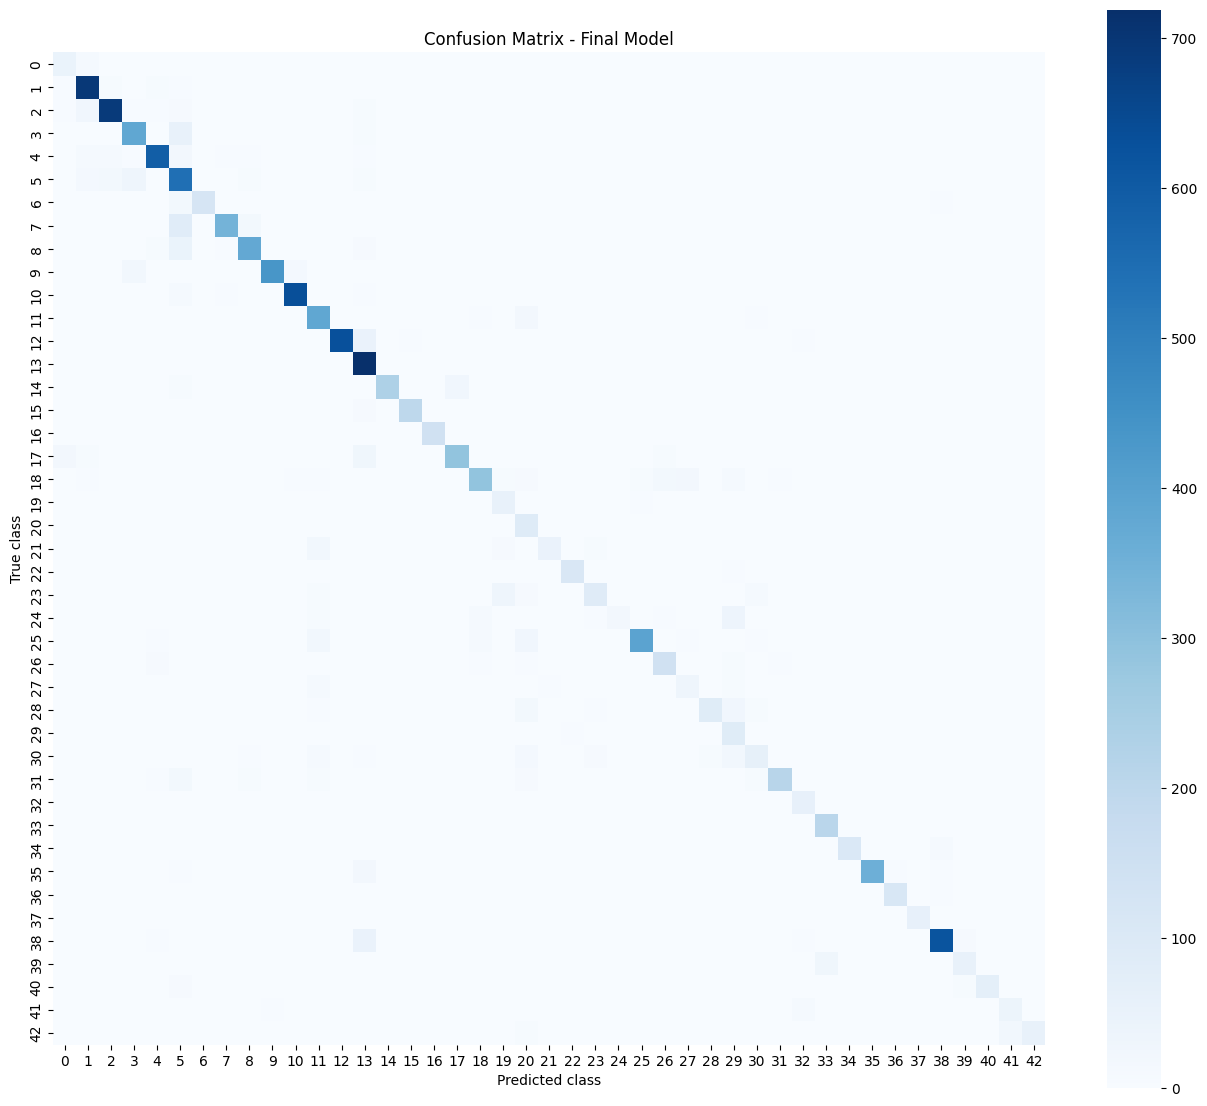

\nPer-class classification report:
              precision    recall  f1-score   support

           0       0.61      0.77      0.68        60
           1       0.89      0.96      0.92       720
           2       0.94      0.92      0.93       750
           3       0.84      0.85      0.84       450
           4       0.93      0.90      0.91       660
           5       0.65      0.86      0.74       630
           6       0.96      0.81      0.88       150
           7       0.94      0.76      0.84       450
           8       0.90      0.84      0.87       450
           9       0.96      0.91      0.94       480
          10       0.96      0.96      0.96       660
          11       0.79      0.91      0.85       420
          12       0.99      0.91      0.95       690
          13       0.77      1.00      0.87       720
          14       1.00      0.87      0.93       270
          15       0.97      0.94      0.95       210
          16       0.99      0.97      0.98   

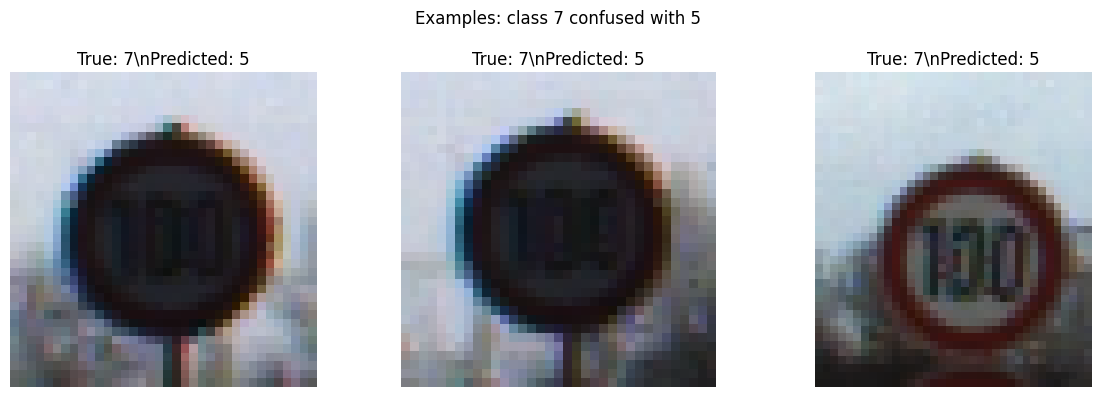

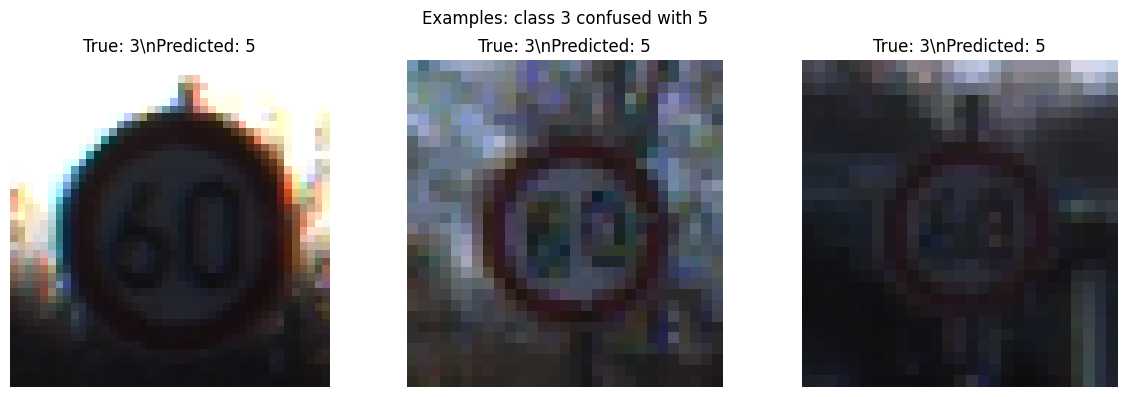

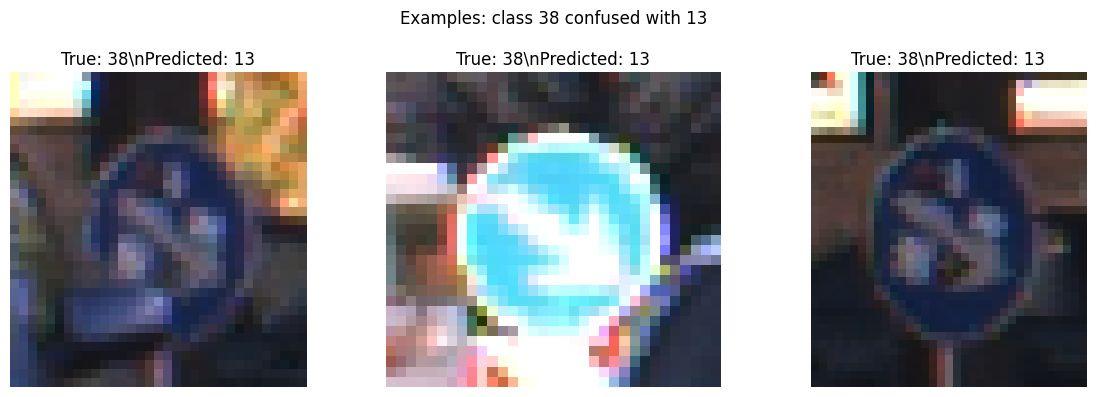

\nAccuracy of the three rarest training classes:
Class 0: train images=150, test accuracy=76.67%
Class 19: train images=150, test accuracy=91.67%
Class 37: train images=150, test accuracy=100.00%


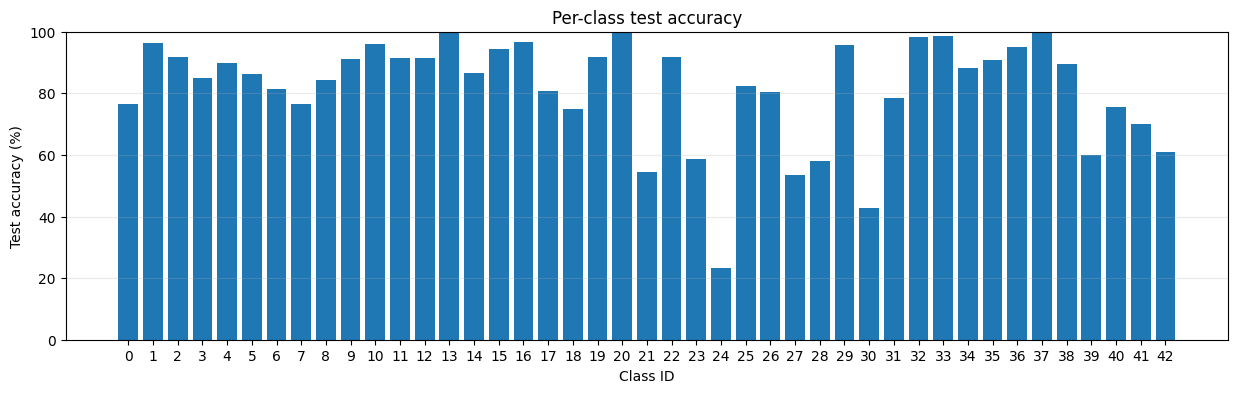

In [15]:
# E1. Collect predictions from the selected final model on the test set
def get_predictions(model, loader):
    model.eval()
    all_true, all_pred = [], []

    with torch.no_grad():
        for batch_images, batch_labels in loader:
            outputs = model(batch_images.to(DEVICE))
            predictions = outputs.argmax(dim=1).cpu().numpy()
            all_pred.extend(predictions.tolist())
            all_true.extend(batch_labels.numpy().tolist())

    return np.array(all_true), np.array(all_pred)


y_true, y_pred = get_predictions(best_model, test_loader)
test_accuracy = (y_true == y_pred).mean()
print(f"Final model: {best_name}")
print(f"Final test accuracy: {test_accuracy * 100:.2f}%")

# Confusion matrix: rows are true classes, columns are predicted classes.
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

plt.figure(figsize=(16, 14))
sns.heatmap(cm, cmap="Blues", square=True, cbar=True)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion Matrix - Final Model")
plt.show()

print("\\nPer-class classification report:")
print(classification_report(
    y_true, y_pred, labels=list(range(NUM_CLASSES)), zero_division=0
))

# E2. Find the three most confused class pairs (largest off-diagonal counts)
cm_without_diagonal = cm.copy()
np.fill_diagonal(cm_without_diagonal, 0)

pair_indices = np.dstack(
    np.unravel_index(np.argsort(cm_without_diagonal.ravel())[::-1],
                     cm_without_diagonal.shape)
)[0]

top_pairs = []
for true_class, predicted_class in pair_indices:
    count = cm[true_class, predicted_class]
    if count == 0:
        break
    # Treat A->B and B->A as the same pair so the list has distinct pairs.
    pair_key = tuple(sorted((int(true_class), int(predicted_class))))
    if pair_key not in [item[0] for item in top_pairs]:
        top_pairs.append((pair_key, int(true_class), int(predicted_class), int(count)))
    if len(top_pairs) == 3:
        break

print("\\nThree most confused class pairs:")
for pair_key, true_class, predicted_class, count in top_pairs:
    print(f"True class {true_class} predicted as {predicted_class}: {count} images")

# Show up to 3 real examples for each confusion pair.
test_paths = [path for path, _ in test_raw._samples]
for _, true_class, predicted_class, count in top_pairs:
    matching = np.where((y_true == true_class) & (y_pred == predicted_class))[0][:3]
    if len(matching) == 0:
        continue

    fig, axes = plt.subplots(1, len(matching), figsize=(4 * len(matching), 4))
    if len(matching) == 1:
        axes = [axes]

    for ax, sample_index in zip(axes, matching):
        image = Image.open(test_paths[sample_index]).convert("RGB")
        ax.imshow(image)
        ax.set_title(f"True: {true_class}\\nPredicted: {predicted_class}")
        ax.axis("off")

    plt.suptitle(f"Examples: class {true_class} confused with {predicted_class}")
    plt.tight_layout()
    plt.show()

# E4. Per-class accuracy and comparison with rare classes from Part A
per_class_accuracy = {}
for class_id in range(NUM_CLASSES):
    class_mask = (y_true == class_id)
    if class_mask.sum() > 0:
        per_class_accuracy[class_id] = (
            (y_pred[class_mask] == y_true[class_mask]).mean()
        )

print("\\nAccuracy of the three rarest training classes:")
for class_id, train_count in rarest_classes:
    print(f"Class {class_id}: train images={train_count}, "
          f"test accuracy={per_class_accuracy.get(class_id, 0) * 100:.2f}%")

plt.figure(figsize=(15, 4))
plt.bar(list(per_class_accuracy.keys()),
        [value * 100 for value in per_class_accuracy.values()])
plt.xlabel("Class ID")
plt.ylabel("Test accuracy (%)")
plt.title("Per-class test accuracy")
plt.xticks(range(NUM_CLASSES))
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.25)
plt.show()

**E3 + E4 analysis (write here):**

The most-confused classes can have signs with similar shapes, colours, symbols, or text. Small images, motion blur, shadows, poor lighting, and partly hidden signs can also remove useful visual details. Check the example images above before deciding which reason applies to each pair. Compare the accuracy of the three rarest classes with the overall test accuracy. If a rare class has lower accuracy, the model may not have seen enough examples of that sign during training. Class weighting can help, but the printed results should be used to support the conclusion.

---
## Part F — Stretch goals  *(bonus +10%)*

**Hints**
- Robustness: wrap the test images with added Gaussian noise / blur / brightness shift and re-measure accuracy; plot accuracy vs. corruption strength.
- Explainability: Grad-CAM highlights the pixels that drove the prediction.
- Demo: softmax the logits for one image and print the top-3 classes with confidences.

**TODO (pick one or more)**
- [ ] Robustness curve  ·  [ ] Grad-CAM heatmap  ·  [ ] Top-3 single-image demo


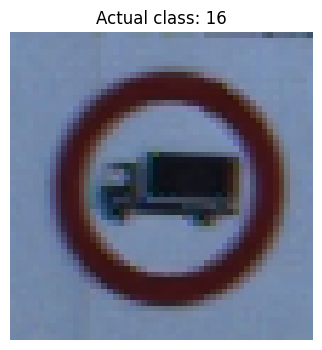

Top 3 predictions:
1. Class 16: 100.00% confidence
2. Class 7: 0.00% confidence
3. Class 9: 0.00% confidence


In [16]:
# F. Stretch goal: show the top-3 predictions and confidence for one test image.
# Softmax converts the model's raw scores into probabilities.
best_model.eval()

sample_index = 0
sample_image, actual_label = test_dataset[sample_index]
with torch.no_grad():
    logits = best_model(sample_image.unsqueeze(0).to(DEVICE))
    probabilities = torch.softmax(logits, dim=1).squeeze(0).cpu()

top3_probabilities, top3_classes = torch.topk(probabilities, k=3)

plt.figure(figsize=(4, 4))
plt.imshow(test_raw[sample_index][0])
plt.title(f"Actual class: {actual_label}")
plt.axis("off")
plt.show()

print("Top 3 predictions:")
for rank, (class_id, probability) in enumerate(
    zip(top3_classes.tolist(), top3_probabilities.tolist()), start=1
):
    print(f"{rank}. Class {class_id}: {probability * 100:.2f}% confidence")

---
## Global hints
- Get the whole pipeline running on a **small subset** before scaling up — a model that trains badly beats a pipeline that won't run.
- "Better" only means something relative to your Part C baseline.
- Don't let test data leak into training or into augmentation statistics.
- `CrossEntropyLoss` wants raw logits; don't add a softmax before it.
- PyTorch: `model.train()` vs `model.eval()`, and `optimizer.zero_grad()` every step.


## What to submit & grading
**Submit** this completed notebook (code + outputs visible) and a short report (≈1–2 pages): preprocessing choices, the Part D comparison table, your confusion-matrix analysis, and a reflection on what helped most. State your **final test accuracy**.

| Component | Weight |
|---|---|
| A — Data exploration | 10% |
| B — Preprocessing | 10% |
| C — Baseline CNN | 25% |
| D — Improvements + comparison table | 30% |
| E — Evaluation & error analysis | 15% |
| Report clarity & reflection | 10% |
| F — Stretch goals | +10% bonus |

Grades reward **deliberate, measured** improvement and clear reasoning — not just the highest accuracy. A modest CNN reaches ~95%+ test accuracy here; well-tuned models exceed 98–99%.
